# S15 - Solution for Exercise E15 - Window Functions
<div align="right"><a href="./L15-Fensterfunktionen.ipynb">Switch to German language 🇩🇪</a></div>

To download solution in MATLAB `*.m` file format, please [click here](./l15.m).

Necessary `m`-file:  [`ldtft.m`](./ldtft.m)

---

In contrast to a recursive filter, whose design is based on the transformation of continuous-time IIR systems to discrete-time IIR-systems, the design of non recursive (FIR) systems is based on the approximation of the desired frequency response of the discrete-time system. Due to their constant group delay, mostly linear phase filters are applied, whose design will be analysed in the following. 

FIR systems with linear phase are based on applying windowing to ideal low-pass filters. To keep the linear phase constraint the window functions have to be symmetric.

The most common window functions are the so-called cosine windows which can be defined as

\begin{equation} \tag{II.15.1}
\label{gwfunction}
w[k]= \left \{
\begin{array}{ll}
 a - b \cdot \cos \left(\frac{2\pi}{m} k \right) + c \cdot  \cos \left(\frac{4\pi}{m} k \right) & \hbox{for}\  0 \leq k \leq  m \\
 0  & \hbox{else.}
\end{array}
\right.
\end{equation}

| Windowing            	            | SciPy Python function 	| $a$     | $b$     | $c$    |
| :--------------------------------	|:------------------------	|:-----:  |:------: |:------:|
| Rectangular         	            | `boxcar()`              	| 1.0  	  | 0.0  	| 0.0  	 | 
| von Hann            	            | `hann()`                	| 0.5  	  | 0.5  	| 0.0  	 |
| Hamming                         	| `hamming()`             	| 0.54    | 0.46 	| 0.0  	 |
| Blackman            	            | `blackman()`            	| 0.42 	  | 0.5  	| 0.08 	 |

## Teilaufgabe a: Fenstertyp berechnen

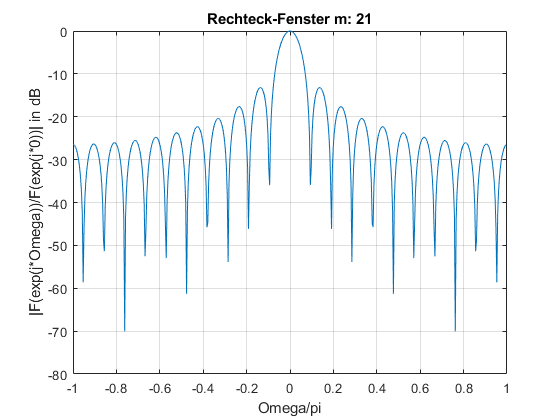

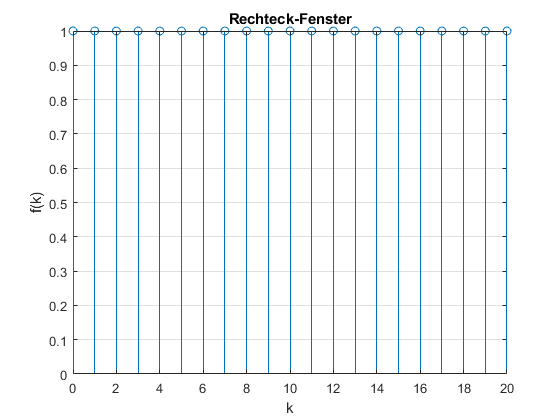

In [2]:
window_length = 21; %für andere Fensterlängen hier die Variable ändern

% Rechteckfenster   
tltstr = 'Rechteck-Fenster';
rw = boxcar(window_length);      % Berechnung des Rechteckfenster der Länge 
                                 % window_length
[Rw,W] = ldtft(rw,512);          % Berechnung der DTFT des Rechteckfensters

i = find(abs(Rw)==0);            % Vermeidung von Werten==0
Rw(i) = 1e-100*ones(size(i));      

% # grafische Ausgabe # %
% normierter Betragsfrequenzgang des Rechteckfensters
figure;                        
plot(W/pi,20*log10(abs(Rw/max(Rw))));
axis([-1 1 -80 0]);
grid;
xlabel('Omega/pi');
ylabel('|F(exp(j*Omega))/F(exp(j*0))| in dB');
title([tltstr,' m: ', num2str(window_length)]); 

% Rechteckfenster
figure; 
stem(0:window_length-1,rw);
grid; 
xlabel('k'); 
ylabel('f(k)'); 
title(tltstr);

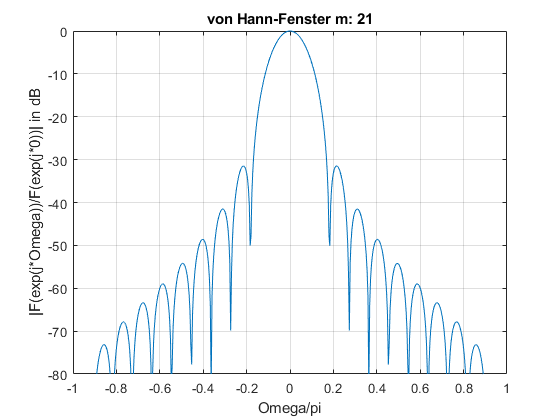

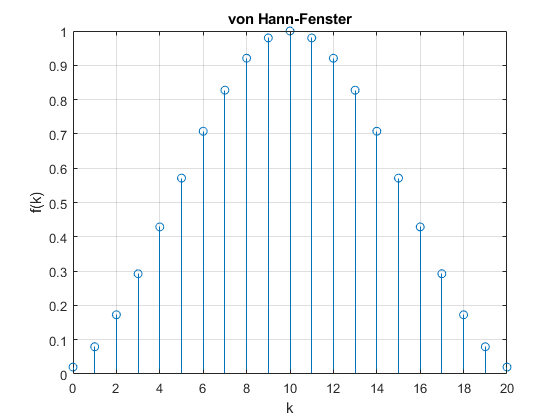

In [3]:
% von Hann
tltstr = 'von Hann-Fenster';
rh = hanning(window_length);      % Berechnung des vonHann-Fenster der Länge
                                  % window_length

[Rh,W] = ldtft(rh,512);           % Berechnung der DTFT des vonHann-Fensters

i = find(abs(Rh)==0);             % Vermeidung von Werten==0
Rh(i) = 1e-100*ones(size(i));

% # grafische Ausgabe # %
% normierter Betragsfrequenzgang des vonHann-Fensters
figure;
plot(W/pi,20*log10(abs(Rh/max(Rh))));
axis([-1 1 -80 0]);
grid;
xlabel('Omega/pi');
ylabel('|F(exp(j*Omega))/F(exp(j*0))| in dB');
title([tltstr,' m: ', num2str(window_length)]);

% vonHann-Fenster
figure; 
stem(0:window_length-1,rh);
grid; xlabel('k'); 
ylabel('f(k)'); 
title(tltstr);


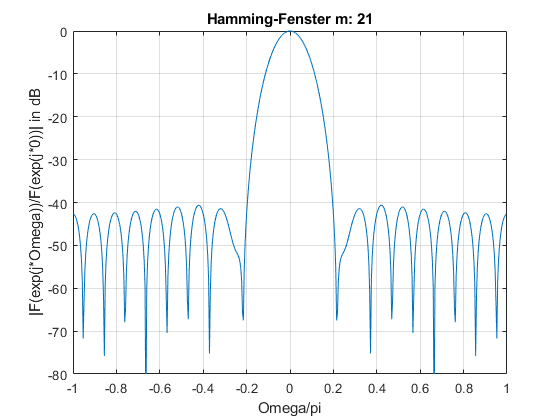

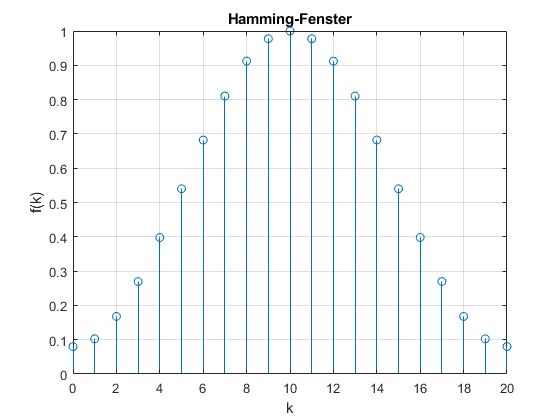

In [4]:
% Hamming
tltstr  = 'Hamming-Fenster';
rhm = hamming(window_length);
[Rhm,W] = ldtft(rhm,512);

i = find(abs(Rhm)==0);
Rhm(i) = 1e-100*ones(size(i)); 

% # grafische Ausgabe # %
% normierter Betragsfrequenzgang des Hamming-Fensters
figure;
plot(W/pi,20*log10(abs(Rhm/max(Rhm))));
axis([-1 1 -80 0]);
grid;
xlabel('Omega/pi');
ylabel('|F(exp(j*Omega))/F(exp(j*0))| in dB');
title([tltstr,' m: ', num2str(window_length)]);

% Hamming-Fenster
figure; 
stem(0:window_length-1,rhm);
grid; xlabel('k'); 
ylabel('f(k)'); 
title(tltstr);


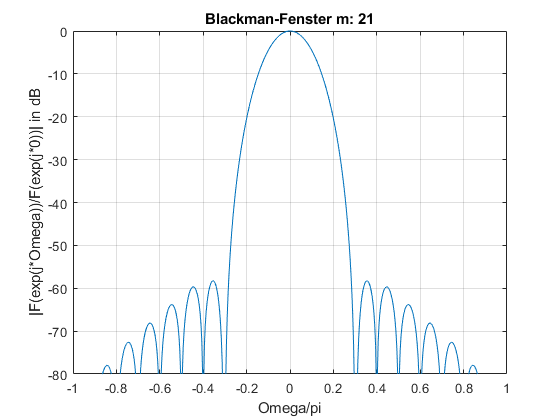

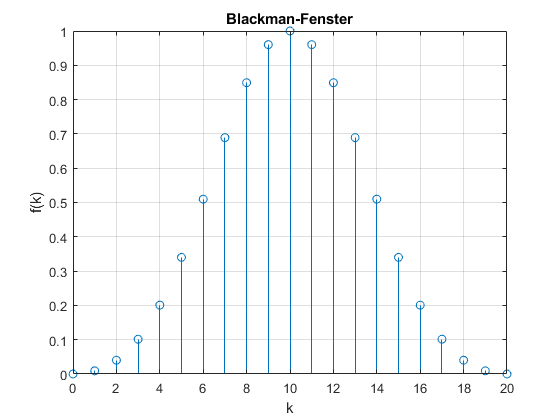

In [6]:
% Blackman
tltstr  = 'Blackman-Fenster';
rhb = blackman(window_length);
[Rhb,W] = ldtft(rhb,512);

i = find(abs(Rhb)==0);                  
Rhb(i) = 1e-100*ones(size(i)); 

figure;
plot(W/pi,20*log10(abs(Rhb/max(Rhb))));
axis([-1 1 -80 0]);
grid;
xlabel('Omega/pi');
ylabel('|F(exp(j*Omega))/F(exp(j*0))| in dB');
title([tltstr,' m: ', num2str(window_length)]);

figure; 
stem(0:window_length-1,rhb);
grid;
xlabel('k');
ylabel('f(k)');
title(tltstr);

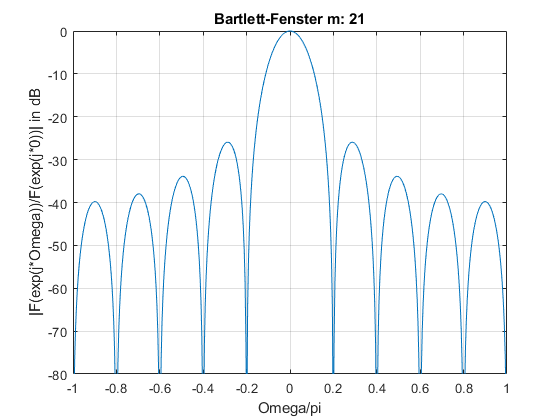

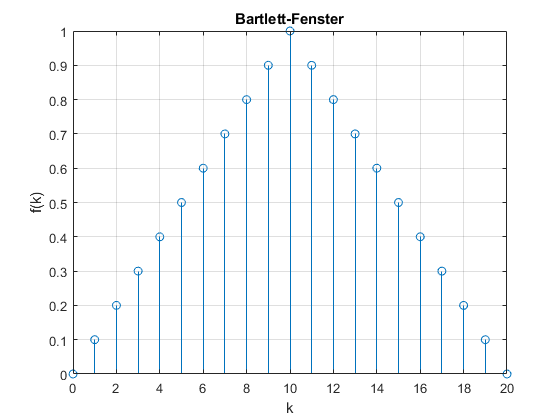

In [7]:
% Bartlett
tltstr  = 'Bartlett-Fenster';
rhbt = bartlett(window_length);
[Rhbt,W] = ldtft(rhbt,512);

i = find(abs(Rhbt)==0);                 
Rhbt(i) = 1e-100*ones(size(i)); 

figure;
plot(W/pi,20*log10(abs(Rhbt/max(Rhbt))));
axis([-1 1 -80 0]);
grid;
xlabel('Omega/pi');    
ylabel('|F(exp(j*Omega))/F(exp(j*0))| in dB');
title([tltstr,' m: ', num2str(window_length)]);

figure; 
stem(0:window_length-1,rhbt)
grid; 
xlabel('k'); 
ylabel('f(k)'); 
title(tltstr);

##  Teilaufgabe b:  Kaiser-Fenster berechnen

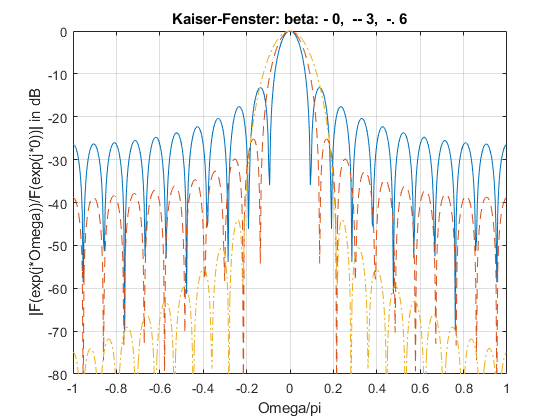

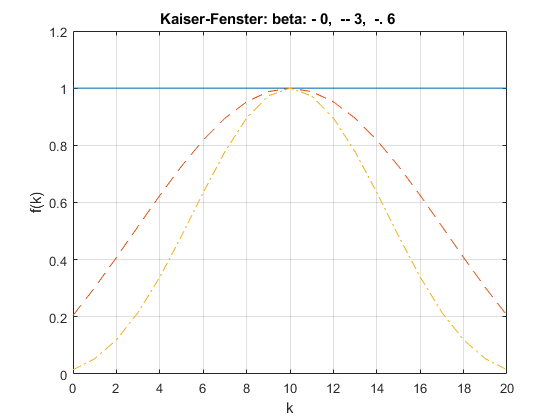

In [8]:
w0 = kaiser(21,0); [W0,W] = ldtft(w0,512);
w3 = kaiser(21,3);     W3 = ldtft(w3,512);
w6 = kaiser(21,6);     W6 = ldtft(w6,512);
k=0:20;

figure; 
plot(W/pi,20*log10(abs(W0/max(W0)))); 
hold on;
plot(W/pi,20*log10(abs(W3/max(W3))),'--');
plot(W/pi,20*log10(abs(W6/max(W6))),'-.'); 
axis([-1 1 -80 0]);
hold off; 
xlabel('Omega/pi'); 
ylabel('|F(exp(j*Omega))/F(exp(j*0))| in dB'); 
title('Kaiser-Fenster: beta: - 0,  -- 3,  -. 6'); 
grid;

figure; 
plot(k,w0); 
hold on; 
plot(k,w3,'--');
plot(k,w6,'-.'); 
axis([0 20 0 1.2]); 
hold off;
xlabel('k');
ylabel('f(k)');
title('Kaiser-Fenster: beta: - 0,  -- 3,  -. 6      '); 
grid;
% #####  EOF  #####